In [1]:
import torch
from matplotlib import pyplot as plt

from mlp_lib.data import load_words, build_vocab, build_dataset, train_dev_test_split
from mlp_lib.model import MLP
from mlp_lib.generate import sample_words

words = load_words("names.txt")

In [2]:
#build vocabulary + train/dev/test split
stoi, itos = build_vocab(words)
vocab_size = len(stoi)
context_len = 3

train_words, dev_words, test_words = train_dev_test_split(words)

In [ ]:
#build tokenized datasets
Xtr, Ytr = build_dataset(train_words, stoi, context_len)
Xdev, Ydev = build_dataset(dev_words, stoi, context_len)
Xtest, Ytest = build_dataset(test_words, stoi, context_len)

In [ ]:
from mlp_lib.layers import Tanh

# random initialization
g = torch.Generator().manual_seed(2147483647)  # for reproducibility

model = MLP(
    vocab_size=vocab_size,
    embed_dim=10,
    context_len=context_len,
    hidden_sizes=[200],   # e.g. [200, 100] for a deeper net
    generator=g,
    activation=Tanh,
)

epochs = 20_000
batch_size = 64

def lr_schedule(epoch):
    return 0.1 if epoch < epochs * 0.75 else 0.01

loss_history = model.train(Xtr, Ytr, epochs=epochs, batch_size=batch_size, lr_schedule=lr_schedule, log_every=1000)

In [5]:
dev_loss, _ = model.loss(Xdev, Ydev)
test_loss, _ = model.loss(Xtest, Ytest)
print(f"dev loss: {dev_loss.item():.4f}")
print(f"test loss: {test_loss.item():.4f}")

dev loss: 2.1450
test loss: 2.1465


In [ ]:
plt.plot(loss_history)

In [7]:
gen_g = torch.Generator().manual_seed(2147483647 + 10)

for word in sample_words(model, stoi, itos, context_len, n=20, generator=gen_g):
    print(word)

carmah
amilli
khi
mili
taty
halaysie
rahnen
delynn
jareei
nellara
chaiivon
leigh
ham
join
quinn
shonne
livabi
wanell
dearyni
jaxeenicraylen


## Forward-Forward (non-backprop baseline)

Same task (predict next char), same context window, but trained without a
global backward pass. See `mlp_lib/ff.py` for the full implementation and
docstrings explaining each step.

**Reframing the task.** Backprop's network answers "given context, what's
the distribution over next chars?" via a softmax output. FF instead answers
"is (context, candidate next char) a real pair or a fake one?" -- the
candidate char is embedded as an extra token appended to the context, so
every input is a `context_len + 1` length sequence.

**Positive / negative data.** Positive = context + the true next char.
Negative = context + a uniformly random *wrong* char. (This is the
"random negative" baseline discussed earlier -- a good first experiment
before trying harder, bigram-weighted negatives.)

**Goodness.** Each hidden layer computes `goodness = sum(activation^2)`
per example -- a scalar "how excited is this layer" signal. Between
layers, activations are L2-normalized before being passed on, so a layer
can't just pass along a big/small vector to fake goodness downstream --
only *direction* carries information forward, magnitude is spent locally.

**Local training (no backprop across layers).** Each layer has its own
loss: `softplus(-y * (goodness - threshold))`, where `y = +1` for
positive examples and `y = -1` for negative ones. This loss shrinks when
goodness rises above `threshold` for positives and falls below it for
negatives. The gradient of *this* loss is computed only with respect to
that layer's own weights (and the embedding, for the first layer) --
never propagated into earlier layers. That's what makes it "forward-only":
credit assignment never leaves the layer that produced it.

**Reading out predictions.** There's no softmax layer to just call
`argmax` on. At inference, every candidate char in the vocabulary is
scored by *total* goodness (summed across layers) for (context,
candidate); those goodness scores are treated as logits, softmax'd, and
sampled -- same sampling mechanism as the backprop model's
`predict_next`, just with goodness standing in for logits.

**Comparable loss metric.** To compare directly against backprop's
cross-entropy, `cross_entropy_readout` does exactly that goodness-as-logits
conversion over the full vocab and reports NLL -- an apples-to-apples
number against the ~2.15 backprop dev loss.

In [ ]:
from mlp_lib.ff import FFNet
from mlp_lib.generate import sample_words_ff

g_ff = torch.Generator().manual_seed(2147483647)
ff_model = FFNet(
    vocab_size=vocab_size,
    embed_dim=10,
    context_len=context_len,
    hidden_sizes=[200],
    generator=g_ff,
    threshold=4.0,     # goodness "decision boundary"; tuned empirically for this hidden size
)

# fixed train subsample (same size as dev) so the tracked train-CE curve
# below is on the same footing as dev, without re-scoring all of Xtr each time
train_eval_ix = torch.randperm(Xtr.shape[0])[:Xdev.shape[0]]
eval_sets = {'train': (Xtr[train_eval_ix], Ytr[train_eval_ix]), 'dev': (Xdev, Ydev)}

ff_history = ff_model.train(
    Xtr, Ytr, epochs=epochs, batch_size=batch_size, lr=0.05, log_every=2000, generator=g_ff,
    eval_sets=eval_sets, eval_every=2000,
)

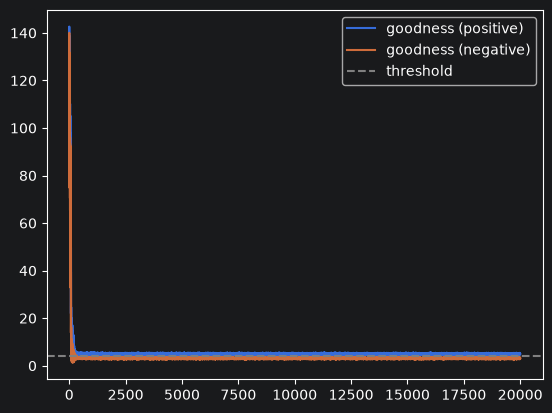

In [9]:
plt.plot(ff_history['goodness_pos'], label='goodness (positive)')
plt.plot(ff_history['goodness_neg'], label='goodness (negative)')
plt.axhline(ff_model.threshold, color='gray', linestyle='--', label='threshold')
plt.legend()

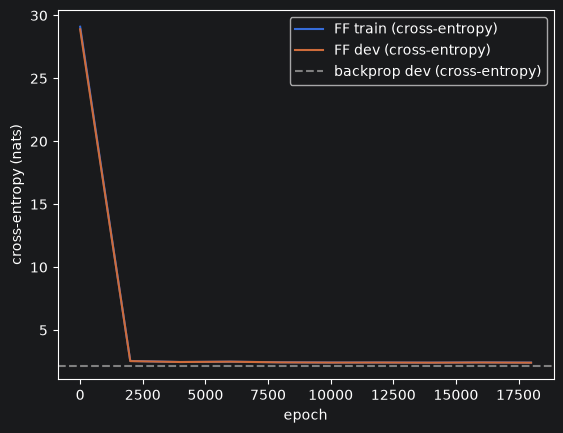

In [10]:
# comparable-to-backprop metric (nats), tracked DURING training -- distinct
# from the goodness-margin loss plotted above, which is a different scale
plt.plot(ff_history['ce_epochs'], ff_history['ce']['train'], label='FF train (cross-entropy)')
plt.plot(ff_history['ce_epochs'], ff_history['ce']['dev'], label='FF dev (cross-entropy)')
plt.axhline(dev_loss.item(), color='gray', linestyle='--', label='backprop dev (cross-entropy)')
plt.xlabel('epoch')
plt.ylabel('cross-entropy (nats)')
plt.legend()

In [11]:
# comparable-to-backprop dev metric: goodness-as-logits cross-entropy
ff_dev_loss, _ = ff_model.cross_entropy_readout(Xdev, Ydev)
ff_test_loss, _ = ff_model.cross_entropy_readout(Xtest, Ytest)

print(f"backprop dev loss (cross-entropy): {dev_loss.item():.4f}")
print(f"FF dev loss       (cross-entropy): {ff_dev_loss.item():.4f}")
print(f"backprop test loss (cross-entropy): {test_loss.item():.4f}")
print(f"FF test loss       (cross-entropy): {ff_test_loss.item():.4f}")

backprop dev loss (cross-entropy): 2.1450
FF dev loss       (cross-entropy): 2.4274
backprop test loss (cross-entropy): 2.1465
FF test loss       (cross-entropy): 2.4261


In [12]:
gen_g_ff = torch.Generator().manual_seed(2147483647 + 10)

for word in sample_words_ff(ff_model, stoi, itos, context_len, n=20, generator=gen_g_ff):
    print(word)

careah
qal
havih
jmrixheety
sacaysa
jazheen
daliaha
kaqei
nelania
ceriiv
kalein
dham
poin
qainthanoilea
vad
qawsathogiearyxi
chaen
dusa
med
ediia
